Dataset Loaded Successfully!
Dataset Shape: (569, 30)
Number of Features: 30
Number of Classes: 2

Dataset Split:
Training Samples: 341
Validation Samples: 114
Testing Samples: 114

Starting Cuckoo Search Optimization...

Iteration 1/20 | Best Fitness: 0.96187
Iteration 2/20 | Best Fitness: 0.96187
Iteration 3/20 | Best Fitness: 0.96187
Iteration 4/20 | Best Fitness: 0.96191
Iteration 5/20 | Best Fitness: 0.96191
Iteration 6/20 | Best Fitness: 0.96191
Iteration 7/20 | Best Fitness: 0.96191
Iteration 8/20 | Best Fitness: 0.96191
Iteration 9/20 | Best Fitness: 0.96191
Iteration 10/20 | Best Fitness: 0.96191
Iteration 11/20 | Best Fitness: 0.96191
Iteration 12/20 | Best Fitness: 0.96191
Iteration 13/20 | Best Fitness: 0.96191
Iteration 14/20 | Best Fitness: 0.96191
Iteration 15/20 | Best Fitness: 0.96191
Iteration 16/20 | Best Fitness: 0.96191
Iteration 17/20 | Best Fitness: 0.96191
Iteration 18/20 | Best Fitness: 0.96191
Iteration 19/20 | Best Fitness: 0.96191
Iteration 20/20 | Best Fitn

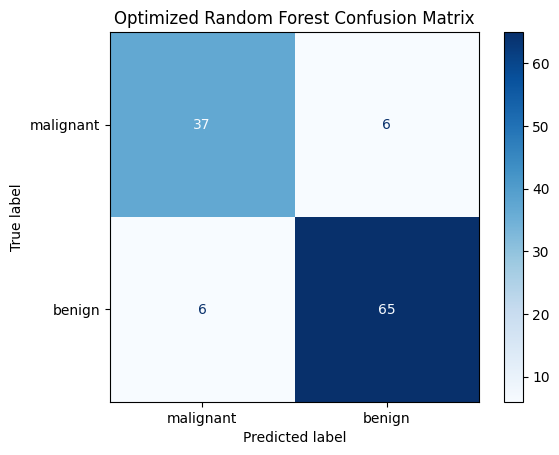

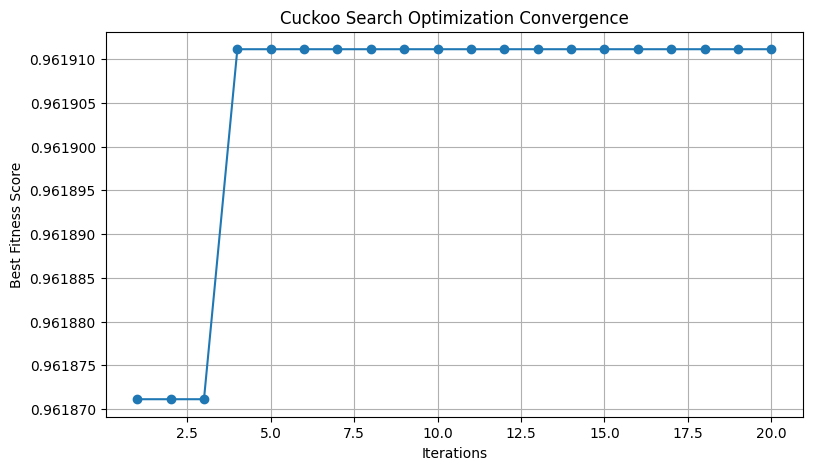

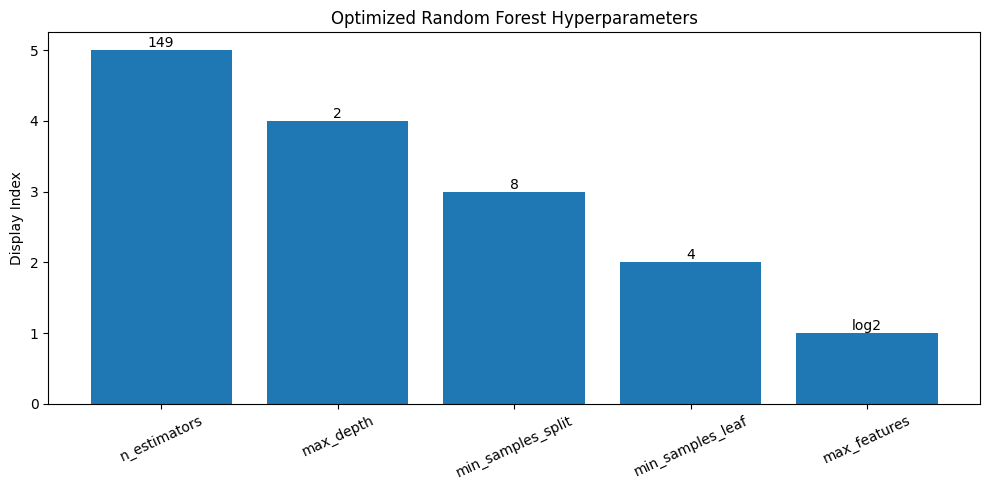


CUCKOO SEARCH OPTIMIZATION COMPLETED
Best Validation Fitness: 0.96191
Final Test Accuracy: 89.47 %
Final Test F1 Score: 0.888


In [12]:

# =====================================================
# MACHINE LEARNING HYPERPARAMETER OPTIMIZATION
# USING CUCKOO SEARCH ALGORITHM
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# 1. LOAD DATASET
# =====================================================

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Loaded Successfully!")
print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Number of Classes:", len(np.unique(y)))


# =====================================================
# 2. SPLIT DATASET
# =====================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nDataset Split:")
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))


# =====================================================
# 3. CUCKOO SEARCH PARAMETERS
# =====================================================

np.random.seed(42)

n_nests = 12
max_iterations = 20
pa = 0.25

# Search boundaries
# [n_estimators, max_depth,
#  min_samples_split, min_samples_leaf, max_features]

lower_bounds = np.array([50, 2, 2, 1, 0])
upper_bounds = np.array([200, 30, 20, 10, 2])

dimension = len(lower_bounds)

# Cache evaluated hyperparameter combinations
fitness_cache = {}


# =====================================================
# 4. DECODE HYPERPARAMETERS
# =====================================================

def decode(solution):

    solution = np.clip(
        solution,
        lower_bounds,
        upper_bounds
    )

    max_features_options = ["sqrt", "log2", None]

    return {
        "n_estimators": int(round(solution[0])),
        "max_depth": int(round(solution[1])),
        "min_samples_split": int(round(solution[2])),
        "min_samples_leaf": int(round(solution[3])),
        "max_features": max_features_options[
            int(round(solution[4]))
        ]
    }


# =====================================================
# 5. FITNESS FUNCTION
# =====================================================

def fitness(solution):

    params = decode(solution)

    # Cache key
    cache_key = tuple(
        params[key]
        for key in [
            "n_estimators",
            "max_depth",
            "min_samples_split",
            "min_samples_leaf",
            "max_features"
        ]
    )

    if cache_key in fitness_cache:
        return fitness_cache[cache_key]

    # Create Random Forest model
    model = RandomForestClassifier(
        **params,
        random_state=42,
        n_jobs=-1
    )

    # Train model
    model.fit(X_train, y_train)

    # Training predictions
    train_predictions = model.predict(X_train)

    train_f1 = f1_score(
        y_train,
        train_predictions,
        average="macro"
    )

    # Validation predictions
    val_predictions = model.predict(X_val)

    val_f1 = f1_score(
        y_val,
        val_predictions,
        average="macro"
    )

    # Overfitting penalty
    overfit_penalty = max(
        0,
        train_f1 - val_f1
    )

    # Final fitness score
    score = val_f1 - 0.2 * overfit_penalty

    fitness_cache[cache_key] = score

    return score


# =====================================================
# 6. LEVY FLIGHT FUNCTION
# =====================================================

def levy_flight(dimension):

    beta = 1.5

    # Precomputed Mantegna sigma
    sigma = 0.6965745

    u = np.random.normal(
        0,
        sigma,
        dimension
    )

    v = np.random.normal(
        0,
        1,
        dimension
    )

    step = u / (
        np.abs(v) ** (1 / beta) + 1e-10
    )

    return step


# =====================================================
# 7. INITIALIZE CUCKOO NESTS
# =====================================================

nests = np.random.uniform(
    lower_bounds,
    upper_bounds,
    size=(n_nests, dimension)
)

fitness_values = np.array([
    fitness(nest) for nest in nests
])

best_index = np.argmax(fitness_values)

best_solution = nests[best_index].copy()

best_score = fitness_values[best_index]

convergence = []

print("\nStarting Cuckoo Search Optimization...\n")


# =====================================================
# 8. CUCKOO SEARCH OPTIMIZATION
# =====================================================

for iteration in range(max_iterations):

    for i in range(n_nests):

        # Generate new solution using Levy flight
        step = levy_flight(dimension)

        new_solution = (
            nests[i]
            + 0.1 * step * (upper_bounds - lower_bounds)
        )

        # Apply search boundaries
        new_solution = np.clip(
            new_solution,
            lower_bounds,
            upper_bounds
        )

        new_score = fitness(new_solution)

        # Select random nest
        j = np.random.randint(n_nests)

        # Replace weaker nest
        if new_score > fitness_values[j]:

            nests[j] = new_solution.copy()

            fitness_values[j] = new_score

        # Update global best
        if new_score > best_score:

            best_score = new_score

            best_solution = new_solution.copy()

    # Abandon worst nests
    n_abandon = max(
        1,
        int(pa * n_nests)
    )

    worst_indices = np.argsort(
        fitness_values
    )[:n_abandon]

    for index in worst_indices:

        new_nest = np.random.uniform(
            lower_bounds,
            upper_bounds
        )

        new_score = fitness(new_nest)

        nests[index] = new_nest

        fitness_values[index] = new_score

        if new_score > best_score:

            best_score = new_score

            best_solution = new_nest.copy()

    convergence.append(best_score)

    print(
        f"Iteration {iteration + 1}/{max_iterations} "
        f"| Best Fitness: {best_score:.5f}"
    )


# =====================================================
# 9. DISPLAY OPTIMAL HYPERPARAMETERS
# =====================================================

best_params = decode(best_solution)

print("\n======================================")
print("OPTIMAL HYPERPARAMETERS")
print("======================================")

for key, value in best_params.items():

    print(f"{key}: {value}")

print("\nBest Fitness Score:", round(best_score, 5))


# =====================================================
# 10. TRAIN FINAL OPTIMIZED MODEL
# =====================================================

final_model = RandomForestClassifier(
    **best_params,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)


# =====================================================
# 11. MODEL EVALUATION
# =====================================================

train_predictions = final_model.predict(X_train)

val_predictions = final_model.predict(X_val)

test_predictions = final_model.predict(X_test)

train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

val_accuracy = accuracy_score(
    y_val,
    val_predictions
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro"
)

print("\n======================================")
print("MODEL PERFORMANCE")
print("======================================")

print(
    "Training Accuracy:",
    round(train_accuracy * 100, 2), "%"
)

print(
    "Validation Accuracy:",
    round(val_accuracy * 100, 2), "%"
)

print(
    "Testing Accuracy:",
    round(test_accuracy * 100, 2), "%"
)

print(
    "Testing F1 Score:",
    round(test_f1, 4)
)


# =====================================================
# 12. CLASSIFICATION REPORT
# =====================================================

print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=data.target_names
    )
)


# =====================================================
# 13. CONFUSION MATRIX
# =====================================================

cm = confusion_matrix(
    y_test,
    test_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues")

plt.title("Optimized Random Forest Confusion Matrix")

plt.show()


# =====================================================
# 14. CUCKOO SEARCH CONVERGENCE GRAPH
# =====================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, max_iterations + 1),
    convergence,
    marker="o"
)

plt.xlabel("Iterations")

plt.ylabel("Best Fitness Score")

plt.title("Cuckoo Search Optimization Convergence")

plt.grid(True)

plt.show()


# =====================================================
# 15. HYPERPARAMETER VISUALIZATION
# =====================================================

parameter_names = list(best_params.keys())

parameter_values = [
    str(value) for value in best_params.values()
]

plt.figure(figsize=(10, 5))

plt.bar(
    parameter_names,
    range(len(parameter_names), 0, -1)
)

plt.xticks(rotation=25)

plt.ylabel("Display Index")

plt.title("Optimized Random Forest Hyperparameters")

for i, value in enumerate(parameter_values):

    plt.text(
        i,
        len(parameter_names) - i,
        value,
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()


# =====================================================
# 16. FINAL RESULT
# =====================================================

print("\n======================================")
print("CUCKOO SEARCH OPTIMIZATION COMPLETED")
print("======================================")

print("Best Validation Fitness:", round(best_score, 5))

print("Final Test Accuracy:", round(test_accuracy * 100, 2), "%")

print("Final Test F1 Score:", round(test_f1, 4))
